## Simulador de paso de mensajes y algoritmos de consenso en redes estocasticas

Es `pruebas.ipynb` del proyecto original (`../Simulador/back/`), puesto al día: las
funciones ya no se definen aquí, se importan del motor que usa la aplicación
(`python/simulation/`). Así este notebook corre exactamente lo mismo que el
simulador. Las diferencias con el original están en `docs/MOTOR.md`.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.dont_write_bytecode = True     # no dejar .pyc dentro de python/
sys.path.insert(0, "../python")

from simulation.algoritmos import ALGORITMOS, amp, fv, fv_batch, amp_batch
from simulation.barrido import round_batch
from simulation.ronda import get_adj, get_values, update_graph_data, who_gets_message

ex = "./k2.json"

### load_graph(file)
Esta función se encarga de cargar el archivo JSON del path

In [2]:
def load_graph(file):
    with open(file, "r") as j:
        return json.load(j)

def graph_info(data):
    nodes = data['nodes']
    edges = data['edges']
    directed = data['directed']

    print(f"Dirigida: {directed}")
    print(f"Nodos: {len(nodes)}")
    print(f"Aristas: {len(edges)}\n")

    print("=== Nodos ===")
    for node in nodes:
        print(f"  {node['id']} | valor: {node['value']}")

    print("\n=== Aristas ===")
    for edge in edges:
        arrow = "->" if directed else "<->"
        print(f"  {edge['id']} | {edge['source']} {arrow} {edge['target']} | p: {edge['weight']}")

def discrepancy(values):
    return max(values) - min(values)

In [3]:
data = load_graph(ex)
print(data)
matrix = get_adj(data)
print(matrix)
values = get_values(data)
print(values)

graph_info(data)
messages, probs = who_gets_message(matrix, data['directed'])
print(messages)
print(probs)

{'directed': True, 'nodes': [{'id': 'node_10', 'value': 1, 'position': {'x': 326.00974172697994, 'y': 368.45561481280527}}, {'id': 'node_11', 'value': 0, 'position': {'x': 495.6295911360882, 'y': 370.795198942586}}], 'edges': [{'id': 'edge_0', 'source': 'node_10', 'target': 'node_11', 'weight': '1'}, {'id': 'edge_1', 'source': 'node_11', 'target': 'node_10', 'weight': '1'}]}
[[0. 1.]
 [1. 0.]]
[1 0]
Dirigida: True
Nodos: 2
Aristas: 2

=== Nodos ===
  node_10 | valor: 1
  node_11 | valor: 0

=== Aristas ===
  edge_0 | node_10 -> node_11 | p: 1
  edge_1 | node_11 -> node_10 | p: 1
[[0 1]
 [1 0]]
[[0.         0.79458936]
 [0.18392433 0.        ]]


### Los algoritmos
`fv` y `amp` reciben `(matrix, values, messages, params)` y devuelven una lista de
`(valor_nuevo, emisor_elegido)`. A diferencia del original ya no devuelven la
discrepancia: se calcula aparte. `amp` toma `agreed` de `params`.

In [4]:
new_values = amp(matrix, values, messages, {"agreed": 0.5})
print("Valores: ", new_values)
print("Discrepancia: ", discrepancy([v[0] for v in new_values]))

Valores:  [(0.5, None), (0.5, None)]
Discrepancia:  0.0


In [5]:
new_values = fv(matrix, values, messages, {})
print("Valores: ", new_values)
print("Discrepancia: ", discrepancy([v[0] for v in new_values]))

Valores:  [(np.int64(0), 1), (np.int64(1), 0)]
Discrepancia:  1


### Codigo para una ronda
Una ronda se compone por:
- Calcular la matriz de mensajes
- Hacer el paso de mensajes con esa matriz y el algoritmo
- Devolver la matriz de valores actualizada

Cualquier algoritmo de `ALGORITMOS` sirve: se pasa su función `ronda`.

In [6]:
def round(algoritmo, matrix, values, times=1, params=None):
    new_values = []
    aux = values.copy()
    for i in range(times):
        messages, probs = who_gets_message(matrix, data['directed'])
        result = algoritmo(matrix, aux, messages, params or {})
        aux = np.array([v[0] for v in result])   # <- solo los valores, descarta el emisor
        new_values.append([aux, discrepancy(aux)])
    return new_values

new_values = round(ALGORITMOS["amp"]["ronda"], matrix, values)
print("Valores: ", new_values[-1][0])
print("Discrepancia: ", new_values[-1][1])

Valores:  [0.5 0.5]
Discrepancia:  0.0


### Version vectorizada (batch)
Igual que `round`, pero sobre `S` simulaciones a la vez (formas `(S, n)`).
`who_gets_message_batch`, `fv_batch`, `amp_batch` y `round_batch` viven en el motor.
Ojo: aquí `fired[s, source, target]` **no** está transpuesta.

### Gráficas de discrepancia
Calculamos la discrepancia de AMP y FV en un rango de probabilidades [0, 1] con saltos de 0.005, y vemos si son correctas

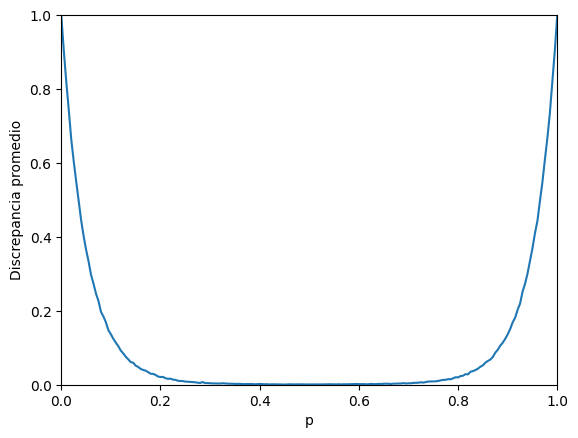

In [7]:
CANTSIM = 20000
TIMES = 10
AGREED = 0.5
ALGORITMO = "fv"        # <- cualquier clave de ALGORITMOS que tenga "batch": "fv" o "amp"

base_matrix = get_adj(data)
edge_mask = base_matrix > 0
directed = data['directed']

# linspace: 201 puntos uniformes en [0, 1] con AMBOS extremos exactos (incluye p = 1.0).
probabilities = np.linspace(0, 1, 201)
discrepanciasAverage = []

for p in probabilities:
    matrix = np.where(edge_mask, p, 0.0)
    # round_batch corre las CANTSIM simulaciones en paralelo (vectorizado) con el algoritmo dado
    vals = round_batch(ALGORITMOS[ALGORITMO]["batch"], matrix, values, directed, CANTSIM,
                       times=TIMES, params={"agreed": AGREED})
    disc = vals.max(axis=1) - vals.min(axis=1)           # discrepancia final por simulacion
    discrepanciasAverage.append(disc.mean())

plt.plot(probabilities, discrepanciasAverage)
plt.xlim(0, 1)
plt.ylim(0, np.max(values))
plt.xlabel("p")
plt.ylabel("Discrepancia promedio")
plt.show()

### update_json
Escribe el grafo con los valores nuevos en `<archivo>_updated.json`
(ignorado por git).

In [8]:
def update_json(file, data, new_values):
    new_file = file.replace('.json', '_updated.json')
    with open(new_file, "w") as j:
        json.dump(update_graph_data(data, new_values), j, indent=2)
    return new_file

In [9]:
new_values = fv(get_adj(data), values, who_gets_message(get_adj(data), data['directed'])[0], {})
update_json(ex, data, new_values)

'./k2_updated.json'